# simlake

A versioned data lake for MD trajectories on Zarr + Icechunk. MDAnalysis and xarray
can both read it, from local disk or object storage.

In [1]:
# Setup: two example runs from MDAnalysisTests (adenylate kinase in water), with the
# protein made whole, written into a scratch directory. run1 is the last 6 frames.
import shutil, tempfile, warnings  # noqa: E401
warnings.filterwarnings("ignore")

import MDAnalysis as mda
from MDAnalysis import transformations
from MDAnalysisTests.datafiles import TPR, XTC

workdir = tempfile.mkdtemp()
u = mda.Universe(TPR, XTC)
u.trajectory.add_transformations(transformations.unwrap(u.select_atoms("protein")))
for name, frames in (("run0", slice(None)), ("run1", slice(4, None))):
    with mda.Writer(f"{workdir}/{name}.xtc", u.atoms.n_atoms) as w:
        for ts in u.trajectory[frames]:
            w.write(u.atoms)

## Create a lake and a system

A **system** is one topology. Trajectories of it are **replicas**.

In [2]:
import simlake as sl

lake = sl.Lake.create(f"{workdir}/kinase.lake")
lake.create_system("adk", TPR, metadata={"forcefield": "oplsaa"})
# atoms are split into groups, by default by molecule type, or your own:
#   lake.create_system("adk", TPR, groups={"protein": "protein", "ligand": "resname ATP", ...})

<System 'adk': 47681 atoms (protein 3341, water 44336, ions 4), 0 replica(s)>

## Add trajectories

Reference an existing file in place (nothing is copied), or copy it in, compressed,
with each atom group stored separately.

In [3]:
lake.register("adk", f"{workdir}/run0.xtc", metadata={"temperature": 300})
lake.add_replica("adk", mda.Universe(TPR, f"{workdir}/run1.xtc"), metadata={"temperature": 310});

## Find data

In [4]:
lake.query("SELECT system, replica, storage, n_frames, temperature FROM trajectories")

,system,replica,storage,n_frames,temperature
0,adk,0,virtual:xtc,10,300
1,adk,1,native,6,310


## Analyse with MDAnalysis

A replica is a normal `Universe`.

In [5]:
from MDAnalysis.analysis import rms

u = lake.universe("adk", replica=0)
rms.RMSD(u, select="backbone").run().results.rmsd[:, 2].round(2)

array([0.  , 1.13, 1.67, 1.98, 1.95, 1.61, 1.61, 1.83, 1.86, 1.64])

In [6]:
protein = lake.universe("adk", replica=1, groups="protein")  # reads only the protein's chunks
protein

<Universe with 3341 atoms>

In [7]:
mda.Universe("simlake://" + lake.location + "?system=adk&replica=1")  # or by URI

<Universe with 47681 atoms>

## Analyse with xarray + dask

`open_dataset` puts every replica in one xarray Dataset, padded to the longest along
`frame`. No coordinates are read: every variable is a **dask array**, a grid of chunks
that maps onto the chunks stored in the lake.

In [8]:
ds = lake.open_dataset("adk")
ds

<xarray.Dataset> Size: 15MB
Dimensions:       (replica: 2, frame: 10, box_vector: 3, spatial: 3, atom: 47681)
Coordinates:
  * replica       (replica) int64 16B 0 1
  * frame         (frame) int64 80B 0 1 2 3 4 5 6 7 8 9
  * spatial       (spatial) <U1 12B 'x' 'y' 'z'
  * atom          (atom) int64 381kB 0 1 2 3 4 ... 47676 47677 47678 47679 47680
    atom_group    (atom) <U7 1MB 'protein' 'protein' 'protein' ... 'ions' 'ions'
    atom_name     (atom) <U4 763kB 'N' 'H1' 'H2' 'H3' ... 'NA' 'NA' 'NA' 'NA'
    atom_resname  (atom) <U4 763kB 'MET' 'MET' 'MET' 'MET' ... 'NA+' 'NA+' 'NA+'
    atom_resid    (atom) int64 381kB 1 1 1 1 1 ... 11298 11299 11300 11301 11302
Dimensions without coordinates: box_vector
Data variables:
    time          (replica, frame) float64 160B 0.0 100.0 200.0 ... nan nan nan
    step          (replica, frame) int64 160B 0 50000 100000 150000 ... -1 -1 -1
    box           (replica, frame, box_vector, spatial) float32 720B dask.array<chunksize=(1, 6, 3, 3), meta=np.ndarray>
    position      (replica, frame, atom, spatial) float32 11MB dask.array<chunksize=(1, 6, 3341, 3), meta=np.ndarray>
    storage       (replica) <U11 88B 'virtual:xtc' 'native'
    n_frames      (replica) int64 16B 10 6
Attributes:
    simlake_lake:           /tmp/tmpf5u3g7kw/kinase.lake
    simlake_system:         adk
    simlake_ref:            main
    simlake_topology_hash:  sha256:10b8a487da5702302384e162fc33c1141395aa8aed...
    simlake_groups:         protein, water, ions

### 1. The dask array behind a variable

`.data` is the dask array. Each block is one stored chunk (or a batch of XTC frames
for in-place replicas), read only when something needs it.

In [9]:
pos = ds.position
pos.data

dask.array<concatenate, shape=(2, 10, 47681, 3), dtype=float32, chunksize=(1, 6, 14779, 3), chunktype=numpy.ndarray>

In [10]:
print("chunks along each dim:", dict(zip(pos.dims, pos.chunks)))
print("groups:", ds.md.groups, "-> atom chunk edges sit on group boundaries")
print(f"blocks: {pos.data.npartitions} | size if loaded: {pos.nbytes / 2**20:.1f} MB | read so far: 0 bytes")

chunks along each dim: {'replica': (1, 1), 'frame': (6, 4), 'atom': (3341, 14779, 14779, 14778, 4), 'spatial': (3,)}
groups: ['protein', 'water', 'ions'] -> atom chunk edges sit on group boundaries
blocks: 20 | size if loaded: 10.9 MB | read so far: 0 bytes


### 2. Build computations: still lazy

`.md.group()` picks whole atom groups, and `.md.select()` takes any MDAnalysis
selection; both are an `isel` on the `atom` dimension, and only the chunks holding
those atoms will be read. Arithmetic on the result only extends the dask task graph.

In [11]:
ds.md.group("protein").position.data  # one block along atom: the protein's chunks only

dask.array<getitem, shape=(2, 10, 3341, 3), dtype=float32, chunksize=(1, 6, 3341, 3), chunktype=numpy.ndarray>

In [12]:
ca = ds.md.select("name CA").position            # (replica, frame, atom, spatial)
ca

<xarray.DataArray 'position' (replica: 2, frame: 10, atom: 214, spatial: 3)> Size: 51kB
dask.array<getitem, shape=(2, 10, 214, 3), dtype=float32, chunksize=(1, 6, 214, 3), chunktype=numpy.ndarray>
Coordinates:
  * replica       (replica) int64 16B 0 1
  * frame         (frame) int64 80B 0 1 2 3 4 5 6 7 8 9
  * atom          (atom) int64 2kB 4 21 45 64 83 ... 3260 3275 3297 3316 3335
    atom_group    (atom) <U7 6kB 'protein' 'protein' ... 'protein' 'protein'
    atom_name     (atom) <U4 3kB 'CA' 'CA' 'CA' 'CA' ... 'CA' 'CA' 'CA' 'CA'
    atom_resname  (atom) <U4 3kB 'MET' 'ARG' 'ILE' 'ILE' ... 'ILE' 'LEU' 'GLY'
    atom_resid    (atom) int64 2kB 1 2 3 4 5 6 7 ... 208 209 210 211 212 213 214
  * spatial       (spatial) <U1 12B 'x' 'y' 'z'
Attributes:
    units:    Angstrom

In [13]:
rmsf = ((ca - ca.mean("frame")) ** 2).sum("spatial").mean("frame") ** 0.5
rmsd = ds.md.select("backbone").md.rmsd()        # MDAnalysis' QCP kernel, per frame, via xr.apply_ufunc

print(type(rmsf.data).__name__, "with", len(rmsf.data.__dask_graph__()), "tasks")
print(type(rmsd.data).__name__, "with", len(rmsd.data.__dask_graph__()), "tasks")

Array with 186 tasks
Array with 156 tasks


### 3. Your own per-frame function

`xr.apply_ufunc(..., dask="parallelized")` runs a plain NumPy function on every block.
The core dimensions (`atom`, `spatial`) reach the function whole, and dask
handles `replica` and `frame`.

In [14]:
import numpy as np
import xarray as xr


def radius_of_gyration(xyz):
    """xyz: (..., atom, 3) NumPy array -> (...,)"""
    centred = xyz - xyz.mean(axis=-2, keepdims=True)
    return np.sqrt((centred ** 2).sum(axis=-1).mean(axis=-1))


rg = xr.apply_ufunc(
    radius_of_gyration, ca,
    input_core_dims=[["atom", "spatial"]],
    dask="parallelized", output_dtypes=[ca.dtype],
).rename("rg")
rg

<xarray.DataArray 'rg' (replica: 2, frame: 10)> Size: 80B
dask.array<transpose, shape=(2, 10), dtype=float32, chunksize=(1, 6), chunktype=numpy.ndarray>
Coordinates:
  * replica  (replica) int64 16B 0 1
  * frame    (frame) int64 80B 0 1 2 3 4 5 6 7 8 9
Attributes:
    units:    Angstrom

### 4. Run: `dask.compute` with a chosen scheduler

Computing several results in one `dask.compute` call shares the chunk reads between
them. The threaded scheduler is the simplest choice: no pickling and no forking.

In [15]:
import dask
from dask.diagnostics import ProgressBar

with dask.config.set(scheduler="threads", num_workers=8), ProgressBar():
    rmsf, rmsd, rg = dask.compute(rmsf, rmsd, rg)

rmsd.round(2)

[########################################] | 100% Completed | 101.28 ms


<xarray.DataArray 'rmsd' (replica: 2, frame: 10)> Size: 160B
array([[0.  , 1.13, 1.67, 1.98, 1.95, 1.61, 1.61, 1.83, 1.86, 1.64],
       [0.  , 1.4 , 1.31, 1.51, 1.61, 1.93,  nan,  nan,  nan,  nan]])
Coordinates:
  * replica  (replica) int64 16B 0 1
  * frame    (frame) int64 80B 0 1 2 3 4 5 6 7 8 9
Attributes:
    units:    Angstrom

### 5. Scale out with `dask.distributed`

The same code runs on a cluster. `LocalCluster` starts worker processes on this
machine. On HPC, swap in `dask_jobqueue.SLURMCluster`, and in the cloud, Coiled or
Kubernetes. Workers open the lake themselves from the chunk references in the graph.

In [16]:
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=2, threads_per_worker=2, dashboard_address=":0")
client = Client(cluster)
print("dashboard (live while the cluster runs):", client.dashboard_link)

dashboard (live while the cluster runs): http://127.0.0.1:32939/status


In [17]:
backbone = ds.md.select("backbone").position.persist()  # read once, keep in worker memory
rmsd_on_cluster = ds.md.select("backbone").md.rmsd().compute()  # .compute() now runs on the cluster
print("persisted blocks:", backbone.data.npartitions,
      "| same as threaded result:", bool(np.allclose(rmsd_on_cluster, rmsd, equal_nan=True)))

persisted blocks: 4 | same as threaded result: True


In [18]:
client.close()
cluster.close()

Results come back as labelled xarray objects:

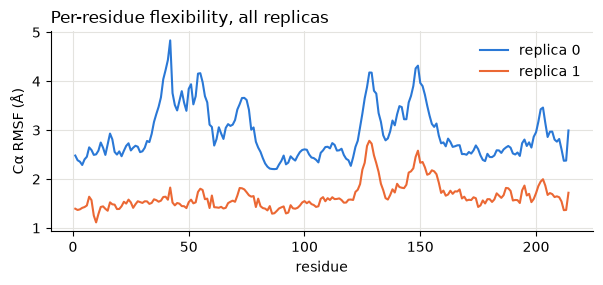

In [19]:
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.axisbelow": True, "legend.frameon": False})
fig, ax = plt.subplots(figsize=(7, 2.6))
for rep, color in zip(rmsf.replica.values, ["#2a78d6", "#eb6834"]):
    ax.plot(ca.atom_resid, rmsf.sel(replica=rep), color=color, lw=1.5, label=f"replica {rep}")
ax.set(xlabel="residue", ylabel="Cα RMSF (Å)", title="Per-residue flexibility, all replicas")
ax.legend();

## Versions

Every write is a commit. Tag what you analysed, and read it back later.

In [20]:
lake.tag("paper-v1")
lake.add_replica("adk", mda.Universe(TPR, f"{workdir}/run1.xtc"))

lake.system("adk").replicas(), lake.system("adk", ref="paper-v1").replicas()

([0, 1, 2], [0, 1])

In [21]:
with lake.transaction("two more replicas") as tx:  # all or nothing
    tx.system("adk").add_replica(mda.Universe(TPR, f"{workdir}/run1.xtc"))
    tx.system("adk").add_replica(mda.Universe(TPR, f"{workdir}/run1.xtc"))

lake.history()[["snapshot", "message"]]

,snapshot,message
0,KMBCWFYEXZW0E0PE4PA0,two more replicas
1,7YKDK42RMXCVVDZ7W79G,add replica to adk
2,6GQN38TYW3DGAZ2JZ25G,add replica to adk
3,GMMDM30C1K132DV41VQ0,register 1 XTC file(s) in adk (virtual)
4,P0NGBS7XESTPWT4BT4F0,create system adk
5,250A3GMSBRMJB4E6WX9G,create lake
6,1CECHNKREP0F1RSTCMT0,Repository initialized


## Check referenced files

In [22]:
lake.verify()

,system,replica,uri,status
0,adk,0,file:///tmp/tmpf5u3g7kw/run0.xtc,ok


## On S3

The same API, with a lake in a bucket and trajectories referenced from another bucket.

In [23]:
# Setup: a local moto server stands in for S3.
import logging, socket
from moto.server import ThreadedMotoServer
logging.getLogger("werkzeug").setLevel(logging.ERROR)
with socket.socket() as s:
    s.bind(("127.0.0.1", 0)); port = s.getsockname()[1]
server = ThreadedMotoServer(ip_address="127.0.0.1", port=port, verbose=False); server.start()
sl.configure("s3://", endpoint_url=f"http://127.0.0.1:{port}", allow_http=True,
             region="us-west-2", access_key_id="demo", secret_access_key="demo")
fs = sl.locations.filesystem("s3://")
fs.mkdir("lakes"); fs.mkdir("raw"); fs.put(f"{workdir}/run0.xtc", "raw/adk/run0.xtc");

In [24]:
cloud = sl.Lake.create("s3://lakes/kinase")
cloud.create_system("adk", TPR)
cloud.register("adk", "s3://raw/adk/run0.xtc")

mda.Universe(cloud.uri("adk", replica=0))

<Universe with 47681 atoms>

In [25]:
cloud.open_dataset("adk").md.select("backbone").md.rmsd().compute().round(2)

<xarray.DataArray 'rmsd' (replica: 1, frame: 10)> Size: 80B
array([[0.  , 1.13, 1.67, 1.98, 1.95, 1.61, 1.61, 1.83, 1.86, 1.64]])
Coordinates:
  * replica  (replica) int64 8B 0
  * frame    (frame) int64 80B 0 1 2 3 4 5 6 7 8 9
Attributes:
    units:    Angstrom

In [26]:
server.stop()
shutil.rmtree(workdir, ignore_errors=True)